# Задание 3

6 вариант: $9x_{1} + 2x_{2}$

Файл: 02_lab_data\task_3.xlsx

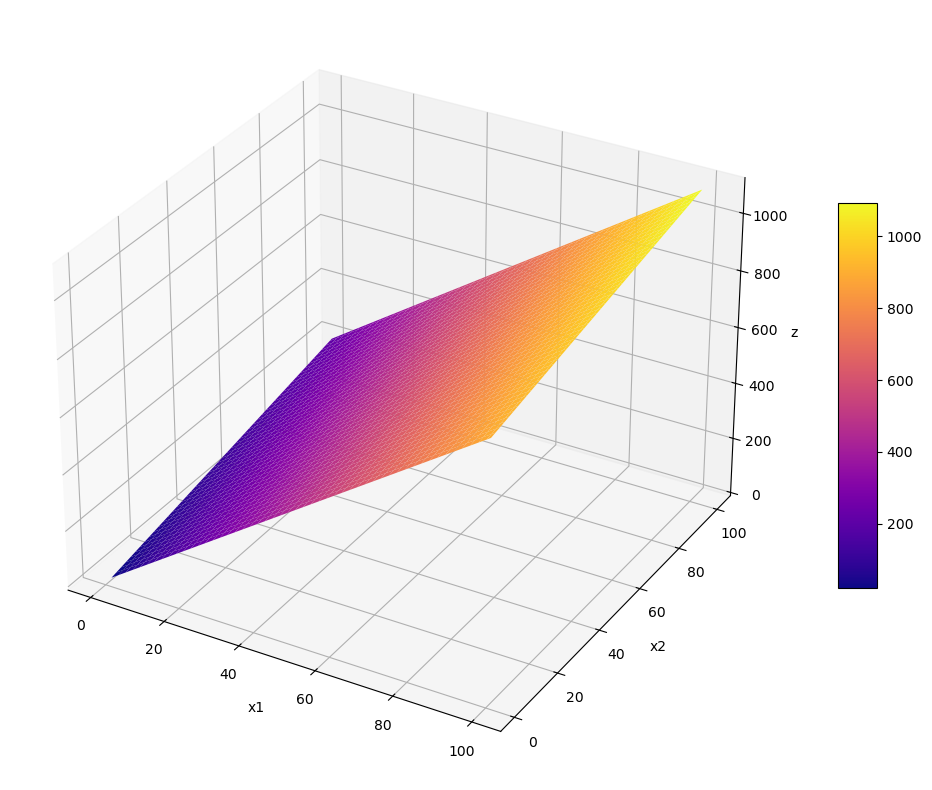

In [27]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_excel('02_lab_data/task_3.xlsx', sheet_name='Лист1', header=None)

x2_vals = df.iloc[0, 1:].astype(float).values
x1_vals = df.iloc[1:, 0].astype(float).values
Z = df.iloc[1:, 1:].astype(float).values

X1, X2 = np.meshgrid(x1_vals, x2_vals, indexing='ij')

fig = plt.figure(figsize=(12, 8))
ax = fig.add_subplot(111, projection='3d')
surf = ax.plot_surface(X1, X2, Z, cmap='plasma', edgecolor='none')

ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('z')
fig.colorbar(surf, shrink=0.5, aspect=10)
plt.tight_layout()
plt.show()

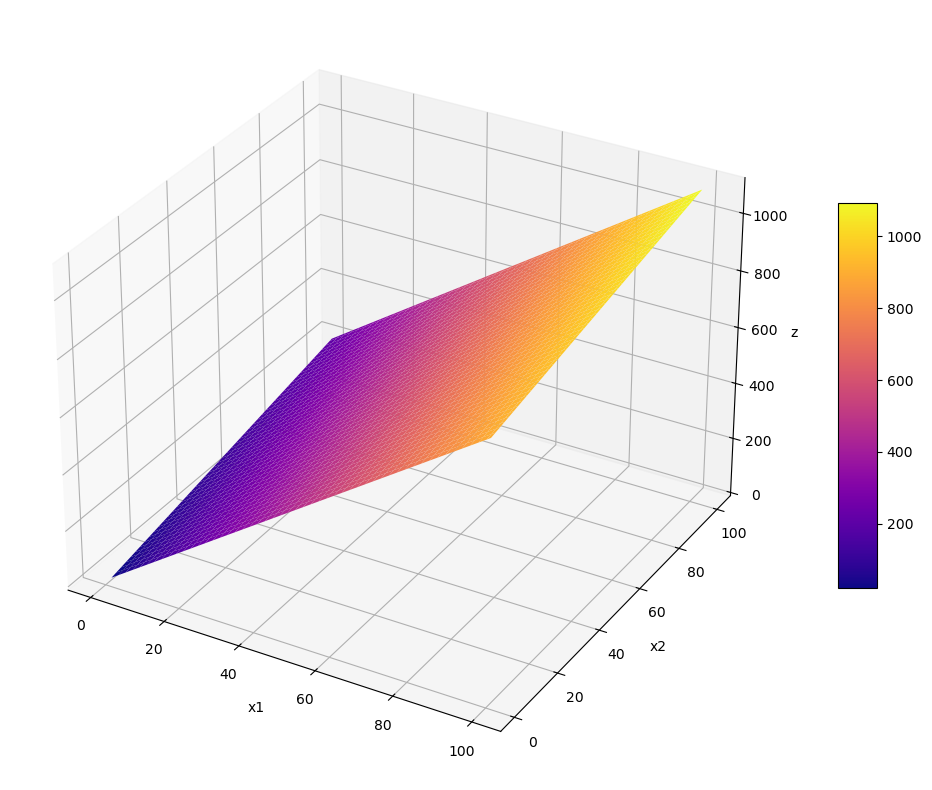

In [28]:
x2_vals_noise = df.iloc[0, 1:].astype(float).values
x1_vals_noise = df.iloc[1:, 0].astype(float).values
Z_noise = df.iloc[1:, 1:].astype(float).values

X1_noise, X2_noise = np.meshgrid(x1_vals_noise, x2_vals_noise, indexing='ij')

rng = np.random.default_rng(seed=42)
Z_noisy = Z_noise + rng.uniform(0.01, 0.1, size=Z_noise.shape)

fig = plt.figure(figsize=(12, 8))
ax_noise = fig.add_subplot(111, projection='3d')
surf = ax_noise.plot_surface(X1_noise, X2_noise, Z_noisy, cmap='plasma', edgecolor='none')

ax_noise.set_xlabel('x1')
ax_noise.set_ylabel('x2')
ax_noise.set_zlabel('z')
fig.colorbar(surf, shrink=0.5, aspect=10)
plt.tight_layout()
plt.show()

Наглядно при большем шуме:
![02_lab_data\with_noise.png](02_lab_data/with_noise.png)

In [29]:
df = pd.DataFrame({
    'x1': X1_noise.ravel(),
    'x2': X2_noise.ravel(),
    'y':  Z_noisy.ravel()
})

print(df.head(10))

df.to_csv('02_lab_data/task_3_long.csv', index=False, encoding='utf-8')

    x1    x2          y
0  1.0   1.0  11.079656
1  1.0   2.0  13.049499
2  1.0   3.0  15.087274
3  1.0   4.0  17.072763
4  1.0   5.0  19.018476
5  1.0   6.0  21.097806
6  1.0   7.0  23.078503
7  1.0   8.0  25.080746
8  1.0   9.0  27.021530
9  1.0  10.0  29.050535


Импорт кода из 2 лабы по ИНС

In [31]:
import numpy as np

class NeuralNetwork:
    weight: np.ndarray
    bias: np.ndarray
    
    def __init__(self, n_neurons: int, n_inputs: int):
        self.weight = np.random.uniform(0.001, 0.2, (n_neurons, n_inputs))
        self.bias = np.zeros(n_neurons)
    
    def _activation_function(self, x: np.ndarray) -> np.ndarray:
        return x
    
    def predict(self, x: np.ndarray) -> np.ndarray:
        if len(x.shape) == 1:
            x = x.reshape(-1, 1)
        weighted_sum = np.dot(self.weight, x) + self.bias.reshape(-1, 1)
        return self._activation_function(weighted_sum).flatten()
    
    def fit_1(self, x: np.ndarray, y: np.ndarray):
        for k in range(len(x)):
            x_k = x[k]
            y_k = y[k]
            y_pred = self.predict(x_k)
            
            for i in range(len(self.weight)):
                sum_x = np.sum(x_k)
                if abs(sum_x) > 1e-10:
                    delta = (y_k[i] - y_pred[i]) / sum_x
                    self.weight[i] += delta
    
    def fit_2(self, x: np.ndarray, y: np.ndarray, alpha: float):
        for k in range(len(x)):
            x_k = x[k].reshape(-1, 1)
            y_k = y[k].reshape(-1, 1)
            y_pred = self.predict(x_k).reshape(-1, 1)
            error = y_pred - y_k
            delta = alpha * np.dot(error, x_k.T)
            self.weight -= delta
    
    def fit(self, x: np.ndarray, y: np.ndarray, alpha: float = 0.01, target_error: float = 0.001, max_epochs: int = 1000):
        epoch = 0
        
        while epoch < max_epochs:
            total_error = 0
            
            for k in range(len(x)):
                x_k = x[k].reshape(-1, 1)
                y_k = y[k].reshape(-1, 1)
                y_pred = self.predict(x_k).reshape(-1, 1)
                error = y_pred - y_k
                delta = alpha * np.dot(error, x_k.T)
                self.weight -= delta
                
                total_error += np.sum(0.5 * (error ** 2))
            
            mse = total_error / len(x)
            
            if mse < target_error:
                break
                
            epoch += 1

def read_data(file: str, has_target: bool = True):
    x_data = []
    y_data = []
    
    with open(file, "r") as data:
        next(data)
        
        for line in data:
            line = line.strip()
            if line:
                values = line.split(",")
                try:
                    float_values = list(map(float, values))
                    if has_target:
                        if len(float_values) == 3:
                            x_data.append(float_values[:2])
                            y_data.append([float_values[2]])
                        elif len(float_values) == 9:
                            x_data.append(float_values[:6])
                            y_data.append(float_values[6:])
                        else:
                            x_data.append(float_values[:-1])
                            y_data.append([float_values[-1]])
                    else:
                        x_data.append(float_values)
                except ValueError:
                    continue
    
    x_data = np.array(x_data, dtype=np.float32)
    y_data = np.array(y_data, dtype=np.float32) if has_target else None
    
    return x_data, y_data

def split_data(x: np.ndarray, y: np.ndarray, train_ratio: float = 0.8, seed: int = 42):
    if len(x) == 0:
        return np.array([]), np.array([]), np.array([]), np.array([])
    
    n = len(x)
    train_size = int(n * train_ratio)
    
    np.random.seed(seed)
    indices = np.random.permutation(n)
    train_idx = indices[:train_size]
    test_idx = indices[train_size:]
    
    x_train = x[train_idx]
    y_train = y[train_idx]
    x_test = x[test_idx]
    y_test = y[test_idx]
    
    return x_train, y_train, x_test, y_test

In [32]:
x_data, y_data = read_data("02_lab_data/task_3_long.csv")
x_train, y_train, x_test, y_test = split_data(x_data, y_data, 0.8)
nn1 = NeuralNetwork(n_neurons=1, n_inputs=2)
nn2 = NeuralNetwork(n_neurons=1, n_inputs=2)

for _ in range(50):
    nn1.fit_1(x_train, y_train)
    nn2.fit_2(x_train, y_train, alpha=0.0001)

print(f"Сеть 1 (метод 1): Веса = {nn1.weight[0]}")
print(f"Сеть 2 (метод 2): Веса = {nn2.weight[0]}")

Сеть 1 (метод 1): Веса = [8.29856503 8.14790141]
Сеть 2 (метод 2): Веса = [9.00078081 2.00029386]
